# Comparing Machine Learning Algorithms for Daily Forest-Fire Detection in Nepal
**Krijal Shrestha — Coventry ID 11495103 — STW7072CEM**

The notebook implements the same experiment reported in the two-column research paper. It compares Logistic Regression, Linear Support Vector Machine, Random Forest, and Histogram Gradient Boosting. The target is a next-day **recorded satellite detection** in a forest-containing grid cell. It is not a verified-fire-absence label or an operational warning.

The frozen run uses 218 of 238 eligible weather locations, covering 348,582 grid-days. Twenty locations were still pending in the 3 November 2026 data snapshot. Results are provisional for Nepal-wide coverage.

## 1. Set-up and reproducibility
Open this notebook from the assignment project directory. The supplied `.weather-venv` contains the recorded dependencies. The downloadable inputs are kept in `data/`; processed data and model results are in `research/`.

Set `REBUILD_ANALYSIS=True` to revalidate the weather manifest and reconstruct the prepared grid-day dataset. Set `RETRAIN_MODELS=True` to run the predefined model comparison again. These options default to `False` so the notebook opens quickly with the frozen, executed results. Source files are not edited.

In [1]:
from pathlib import Path
import json, os, platform
os.environ.setdefault('OMP_NUM_THREADS','2')
os.environ.setdefault('OPENBLAS_NUM_THREADS','2')
os.environ.setdefault('MPLCONFIGDIR',str(Path.cwd()/'tmp/matplotlib'))
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/'research_experiments.py').exists(), 'Open from the project directory.'
REBUILD_ANALYSIS=False
RETRAIN_MODELS=False
print('Python:',platform.python_version())
print('Weather files:',len(list((ROOT/'data/open_meteo_daily').glob('NP_*.csv'))),'/238')


Python: 3.10.1
Weather files: 218 /238


## 2. Data provenance and cleaning

| Dataset | Source and observation period | Role in the experiment |
|---|---|---|
| `Active_Fire_Incidents_in_Nepal.csv` | ICIMOD Regional Database System; MODIS-based records, February 2012–June 2016 | Main recorded-detection labels |
| `NP_*.csv` daily weather | Open-Meteo Historical Weather API, model fixed to ERA5; 2012–2016 | Prior-day temperature, rainfall, humidity and wind |
| `Land cover of Nepal 2011.zip` | FRTC, distributed through ICIMOD | Fixed class-4 forest eligibility mask |
| `rasters_SRTMGL1.tar.gz` | NASA SRTM GL1 via OpenTopography; February 2000 survey | Elevation, slope, aspect context |
| `geoBoundaries-NPL-ADM0.geojson` | geoBoundaries ADM0, metadata year 2019 | Nepal study boundary |

The preprocessing removes 224 repeated detection keys, one point outside the Nepal boundary, and 3,298 points outside the 2011 forest class. It assumes the MODIS-style acquisition time is UTC, converts it to Nepal time, and excludes incomplete first and last days. The source CSV is preserved unchanged. Absence of a recorded detection is not treated as confirmed absence of fire.

In [2]:
if REBUILD_ANALYSIS:
    import research_experiments as experiment
    data, features = experiment.prepare()
else:
    data=pd.read_csv(ROOT/'research/data/forest_fire_grid_daily.csv',parse_dates=['date'])
    features=json.loads((ROOT/'research/data/feature_columns.json').read_text())
audit=json.loads((ROOT/'research/data/preparation_audit.json').read_text())
summary=json.loads((ROOT/'research/results/summary.json').read_text())
display(pd.Series(audit,name='audit').to_frame())
display(data.head())


,audit
source_fire_rows,13781
weather_target_locations,238
study_definition,Forecast next-day recorded fire detection in f...
negative_definition,No recorded detection; absence and satellite o...
invalid_acquisition_times,0
unique_detection_rows,13557
duplicate_detection_rows_removed,224
outside_nepal_rows,1
within_nepal_nonforest_rows,3298
forest_detection_rows,10258


,grid_id,date,temperature_2m_mean_previous_day,temperature_2m_max_previous_day,relative_humidity_2m_mean_previous_day,relative_humidity_2m_min_previous_day,wind_speed_10m_mean_previous_day,wind_speed_10m_max_previous_day,precipitation_previous_1d_mm,precipitation_previous_7d_mm,...,day_of_year_sin,day_of_year_cos,forest_fraction_2011,forest_pixels_2011,elevation_mean_m,slope_mean_degrees,aspect_northness_mean,aspect_eastness_mean,split,dry_days_previous
0,NP_01_32,2012-02-02,16.7,25.5,52.0,18.0,2.68,5.04,0.0,0.0,...,0.537677,0.843151,0.005323,27,66.661754,1.72793,0.012292,-0.009212,train,13.0
1,NP_01_32,2012-02-03,16.1,24.1,58.0,27.0,1.44,2.33,0.0,0.0,...,0.552101,0.833777,0.005323,27,66.661754,1.72793,0.012292,-0.009212,train,14.0
2,NP_01_32,2012-02-04,17.2,27.3,63.0,25.0,2.13,3.01,0.0,0.0,...,0.566362,0.824157,0.005323,27,66.661754,1.72793,0.012292,-0.009212,train,15.0
3,NP_01_32,2012-02-05,18.4,27.5,61.0,32.0,1.55,2.75,0.0,0.0,...,0.580455,0.814292,0.005323,27,66.661754,1.72793,0.012292,-0.009212,train,16.0
4,NP_01_32,2012-02-06,18.7,28.4,64.0,34.0,1.90,3.63,0.0,0.0,...,0.594376,0.804187,0.005323,27,66.661754,1.72793,0.012292,-0.009212,train,17.0


In [3]:
assert data.grid_id.nunique()==218
assert not data.duplicated(['grid_id','date']).any()
assert data[features].notna().all().all()
assert len(features)==21
parts={s:data[data.split.eq(s)] for s in ['train','validation','test']}
assert parts['train'].date.max()<parts['validation'].date.min()<parts['test'].date.min()
display(data.groupby('split').agg(grid_days=('fire_detected','size'),recorded_fire_days=('fire_detected','sum'),prevalence=('fire_detected','mean')))
print('Prediction features:',len(features),features)


,grid_days,recorded_fire_days,prevalence
split,,,
test,37060,1545,0.041689
train,231952,2604,0.011226
validation,79570,195,0.002451


Prediction features: 21 ['temperature_2m_mean_previous_day', 'temperature_2m_max_previous_day', 'relative_humidity_2m_mean_previous_day', 'relative_humidity_2m_min_previous_day', 'wind_speed_10m_mean_previous_day', 'wind_speed_10m_max_previous_day', 'precipitation_previous_1d_mm', 'precipitation_previous_7d_mm', 'precipitation_previous_30d_mm', 'temperature_mean_previous_7d', 'humidity_mean_previous_7d', 'latitude', 'longitude', 'day_of_year_sin', 'day_of_year_cos', 'forest_fraction_2011', 'elevation_mean_m', 'slope_mean_degrees', 'aspect_northness_mean', 'aspect_eastness_mean', 'dry_days_previous']


## 3. Leakage control and feature construction

The prediction target for grid cell $g$ and local day $t$ is one when at least one retained ICIMOD detection occurs in that cell on that day. Weather predictors end at $t-1$. For example, a $k$-day precipitation total is $R^{(k)}_{g,t}=\sum_{j=1}^{k}P_{g,t-j}$ for $k\in\{1,7,30\}$. The 21 inputs also include previous-day weather, previous-week temperature/humidity means, capped dry-day run, season sine/cosine, location, forest fraction and terrain.

Brightness, fire radiative power, confidence, acquisition time, detection counts, and same-day national detection indicators are excluded because they reveal detection information or are unavailable consistently for negative grid-days. All eligible no-detection days are kept. The learned models use class weights; no negative undersampling or synthetic SMOTE examples are used.

In [4]:
assert not set(features)&{'fire_detected','detection_count','national_detection_recorded','BRIGHTNESS','FRP','CONFIDENCE'}
print('Prepared rows:',len(data),' positive grid-days:',int(data.fire_detected.sum()))


Prepared rows: 348582  positive grid-days: 4344


## 4. Models, hyperparameters, and why they are included

| Algorithm | Purpose in this comparison | Candidate settings |
|---|---|---|
| Logistic Regression | Regularised, interpretable linear baseline | StandardScaler fitted on training rows; $C\in\{0.01,0.1,1\}$; balanced weights |
| Linear SVM | Tests a maximum-margin objective on the same scaled feature space | Squared hinge loss; $C\in\{0.01,0.1,1\}$; balanced weights |
| Random Forest | Captures nonlinear thresholds and interactions by bootstrap aggregation | 150 trees; depth 8, 12, or unlimited; minimum leaf 10 |
| Histogram Gradient Boosting | Tests sequential gradient-based correction of nonlinear errors | 150 iterations; 7, 15, or 31 leaves; learning rate 0.08; L2=1 |

Each has a different role: the linear models test whether a simple decision boundary is adequate; the two tree ensembles test nonlinear effects. A constant prior classifier anchors the severe class imbalance. Linear regression, K-means, and reinforcement learning are excluded because the task has binary observed labels and no cluster-only or action/reward target.

## 5. Temporal evaluation and model selection

Training uses 2012–2014, validation uses 2015, and test uses available dates from January through 18 June 2016. Model/hyperparameter selection uses validation average precision (AP), and a separate validation-F1 threshold turns scores into binary decisions. A second policy selects thresholds for validation accuracy to answer the coursework's accuracy comparison directly. Test data do not select hyperparameters or thresholds. All policies are reported alongside an always-negative baseline.

AP is the primary ranking metric because positives are rare. Accuracy is also reported, but compared with the baseline; high accuracy can result from missing almost every positive. SVM values are decision margins rather than probabilities. Weighted outputs are not treated as calibrated fire probabilities. A previous exploratory project run had already used overlapping 2016 outcomes, so the expanded 2016 evaluation is not described as a pristine external test.

In [5]:
if RETRAIN_MODELS:
    import research_experiments as experiment
    experiment.run(data,features)
metrics=pd.read_csv(ROOT/'research/results/metrics.csv')
tuning=pd.read_csv(ROOT/'research/results/tuning.csv')
display(tuning[['model','configuration','validation_ap','validation_accuracy']])
display(metrics[metrics.split.eq('test')][['model','policy','accuracy','balanced_accuracy','average_precision','roc_auc','precision','recall','f1','tn','fp','fn','tp']])
print('Validation AP winner:',summary['selected_by_validation_AP'])


,model,configuration,validation_ap,validation_accuracy
0,Logistic regression,1,0.073490,0.997549
1,Logistic regression,2,0.073806,0.997549
2,Logistic regression,3,0.074011,0.997549
3,Linear SVM,1,0.079214,0.997549
4,Linear SVM,2,0.079387,0.997549
5,Linear SVM,3,0.079392,0.997549
6,Random forest,1,0.036967,0.997549
7,Random forest,2,0.036655,0.997549
8,Random forest,3,0.039643,0.997549
9,Gradient boosting,1,0.051244,0.997549


,model,policy,accuracy,balanced_accuracy,average_precision,roc_auc,precision,recall,f1,tn,fp,fn,tp
1,Logistic regression,F1,0.957501,0.683138,0.374022,0.921380,0.487664,0.383819,0.429555,34892,623,952,593
3,Logistic regression,accuracy,0.957987,0.524285,0.374632,0.921926,0.464706,0.051133,0.092128,35424,91,1466,79
5,Linear SVM,F1,0.955963,0.716076,0.375168,0.921051,0.470825,0.454369,0.462451,34726,789,843,702
7,Linear SVM,accuracy,0.957987,0.526452,0.375059,0.921075,0.467391,0.055663,0.099479,35417,98,1459,86
9,Random forest,F1,0.956854,0.731709,0.459722,0.926555,0.482648,0.486084,0.484360,34710,805,794,751
11,Random forest,accuracy,0.959606,0.523582,0.453496,0.932647,0.740000,0.047896,0.089970,35489,26,1471,74
13,Gradient boosting,F1,0.957690,0.746384,0.470378,0.935605,0.492888,0.515858,0.504111,34695,820,748,797
15,Gradient boosting,accuracy,0.958635,0.505431,0.470378,0.935605,0.772727,0.011003,0.021698,35510,5,1528,17
17,Always no detection,baseline,0.958311,0.500000,0.041689,0.500000,0.000000,0.000000,0.000000,35515,0,1545,0


Validation AP winner: Linear SVM


## 6. Results and colourful figures

The validation-AP winner is Linear SVM (AP 0.0794). On the held-out portion of 2016, Gradient Boosting has the highest AP (0.4704) and F1 (0.5041) among the AP-selected configurations. The accuracy-optimised Random Forest has the greatest test accuracy (95.96%) but recall of only 4.79%; always predicting no detection already gives 95.83% accuracy. The rankings therefore depend on the stated objective, and no method is called universally best.

The figures use consistent colours for each algorithm. Confusion matrices use a logarithmic colour scale with exact counts annotated. These are historical analysis figures, not fire warning maps.

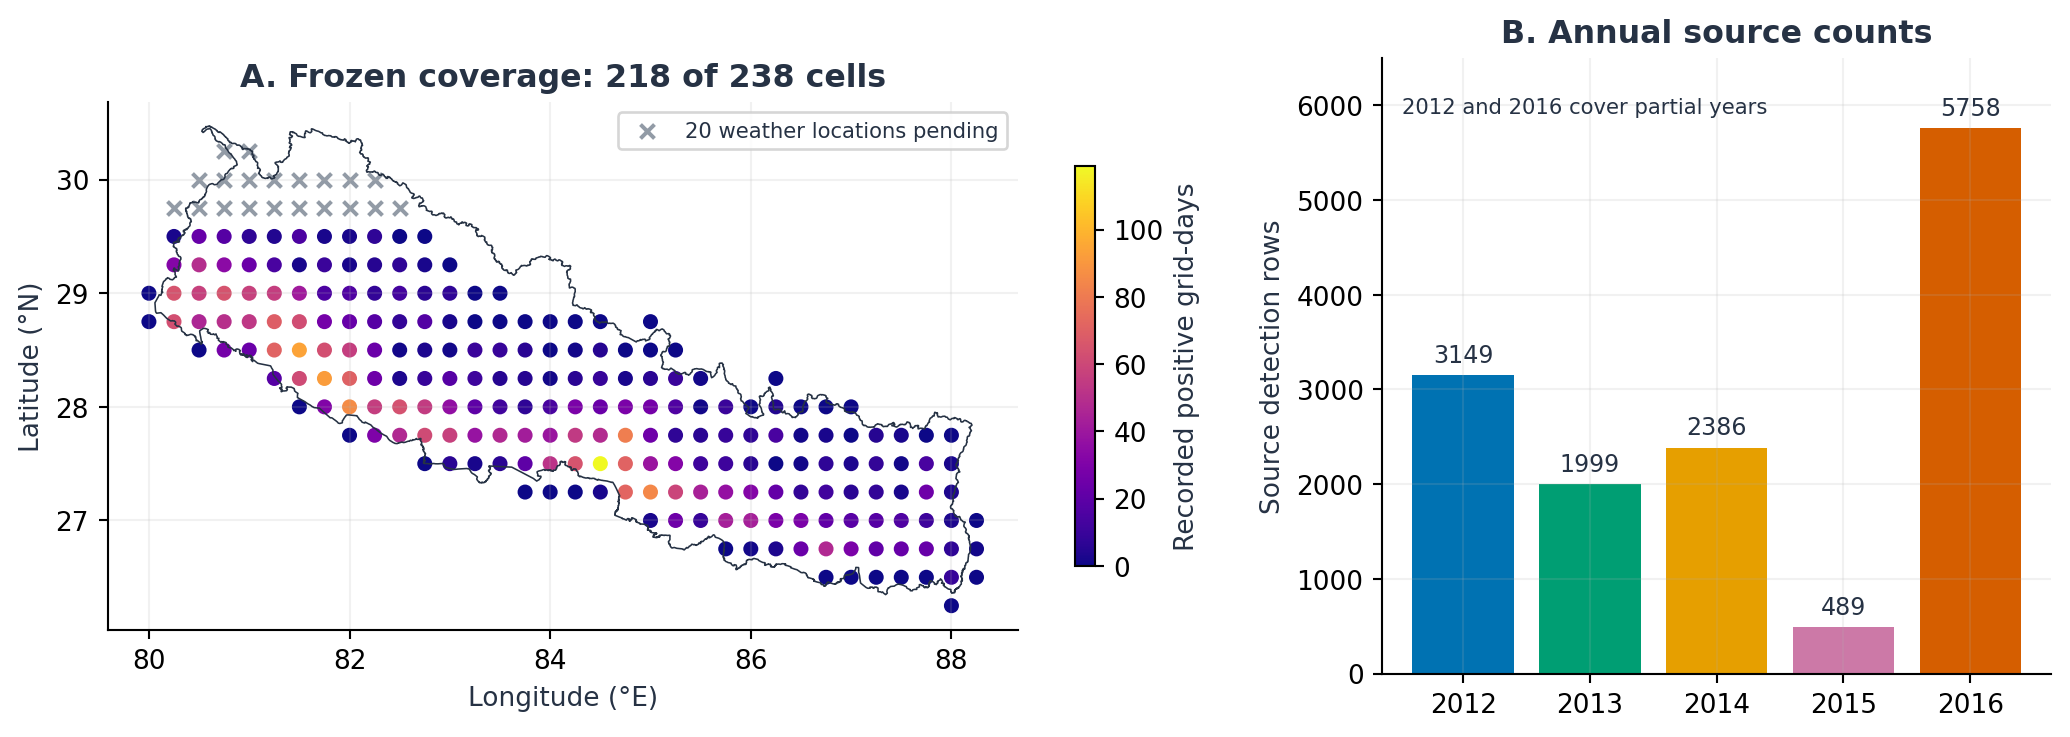

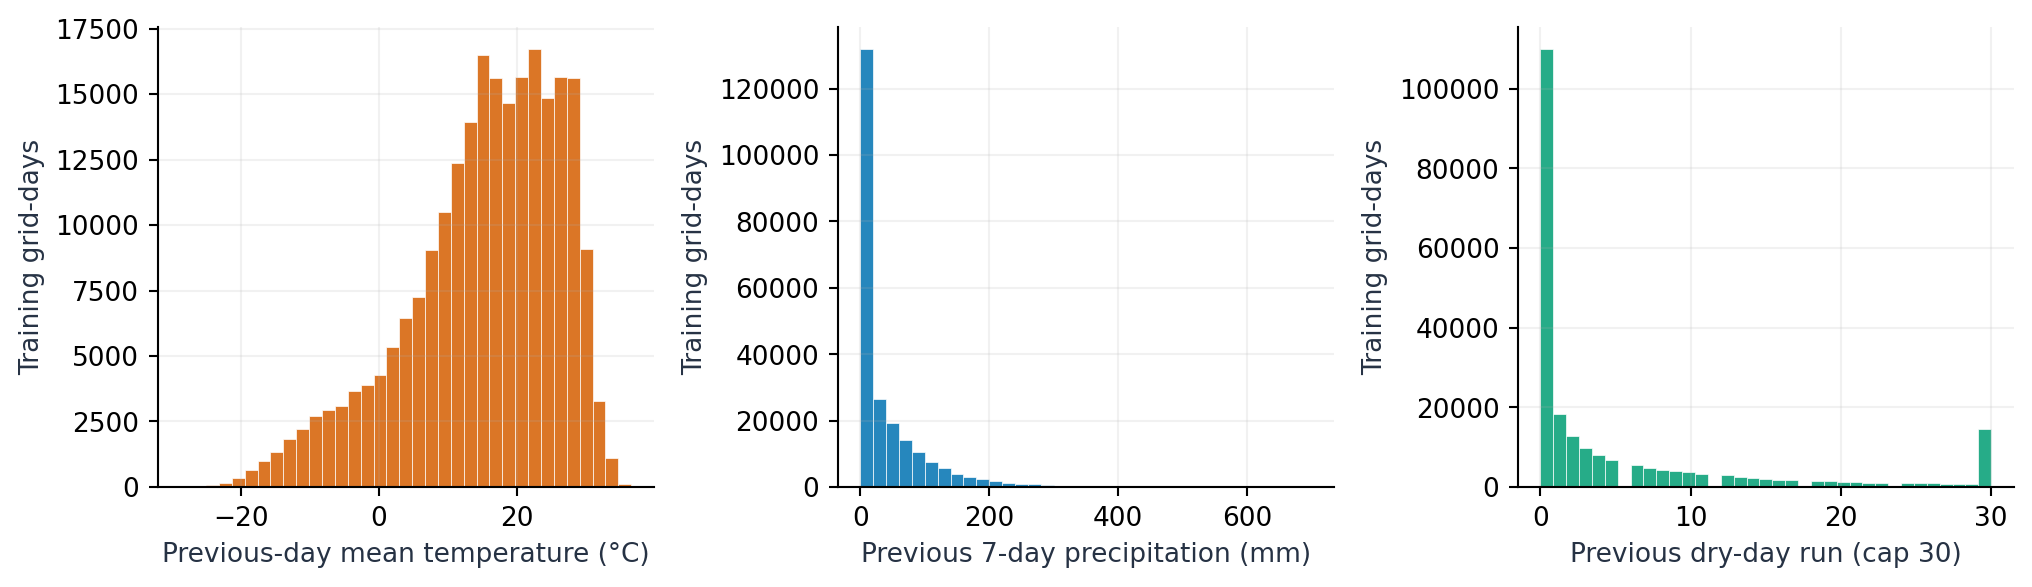

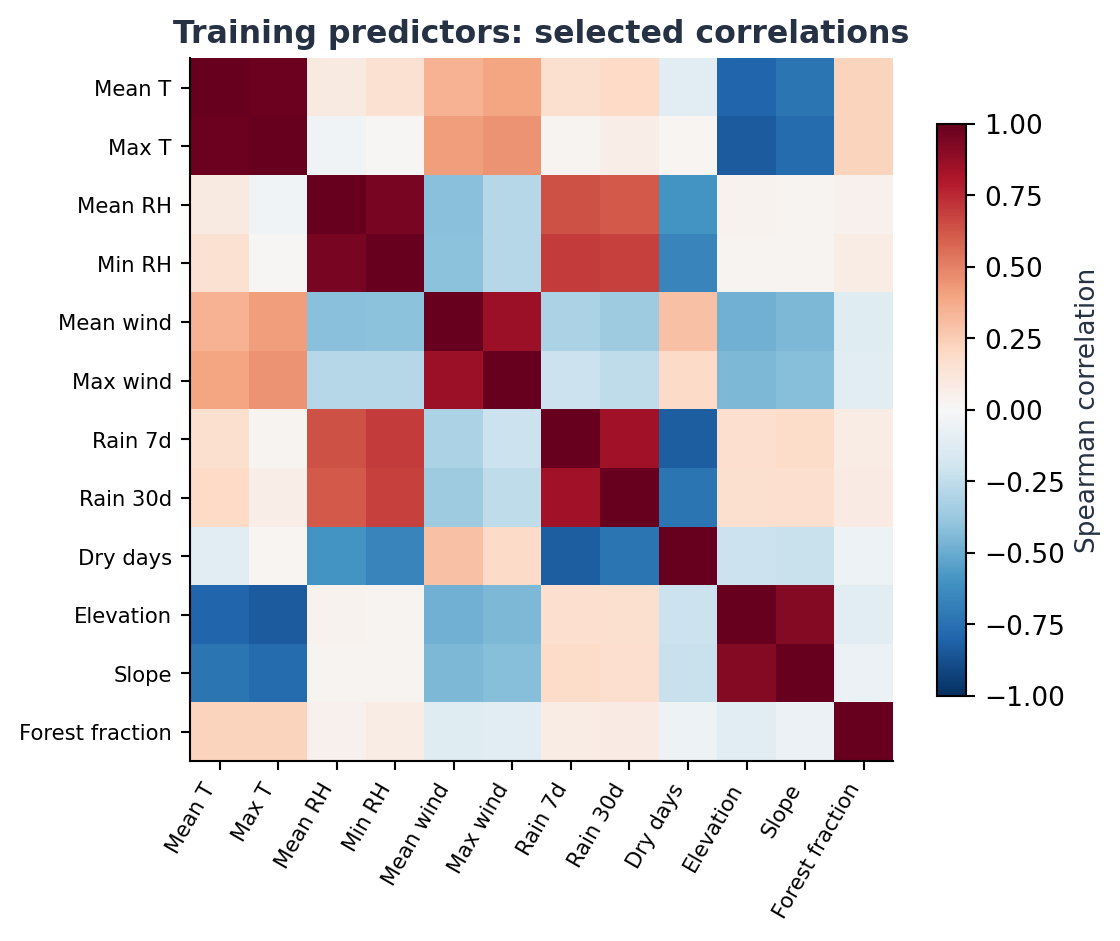

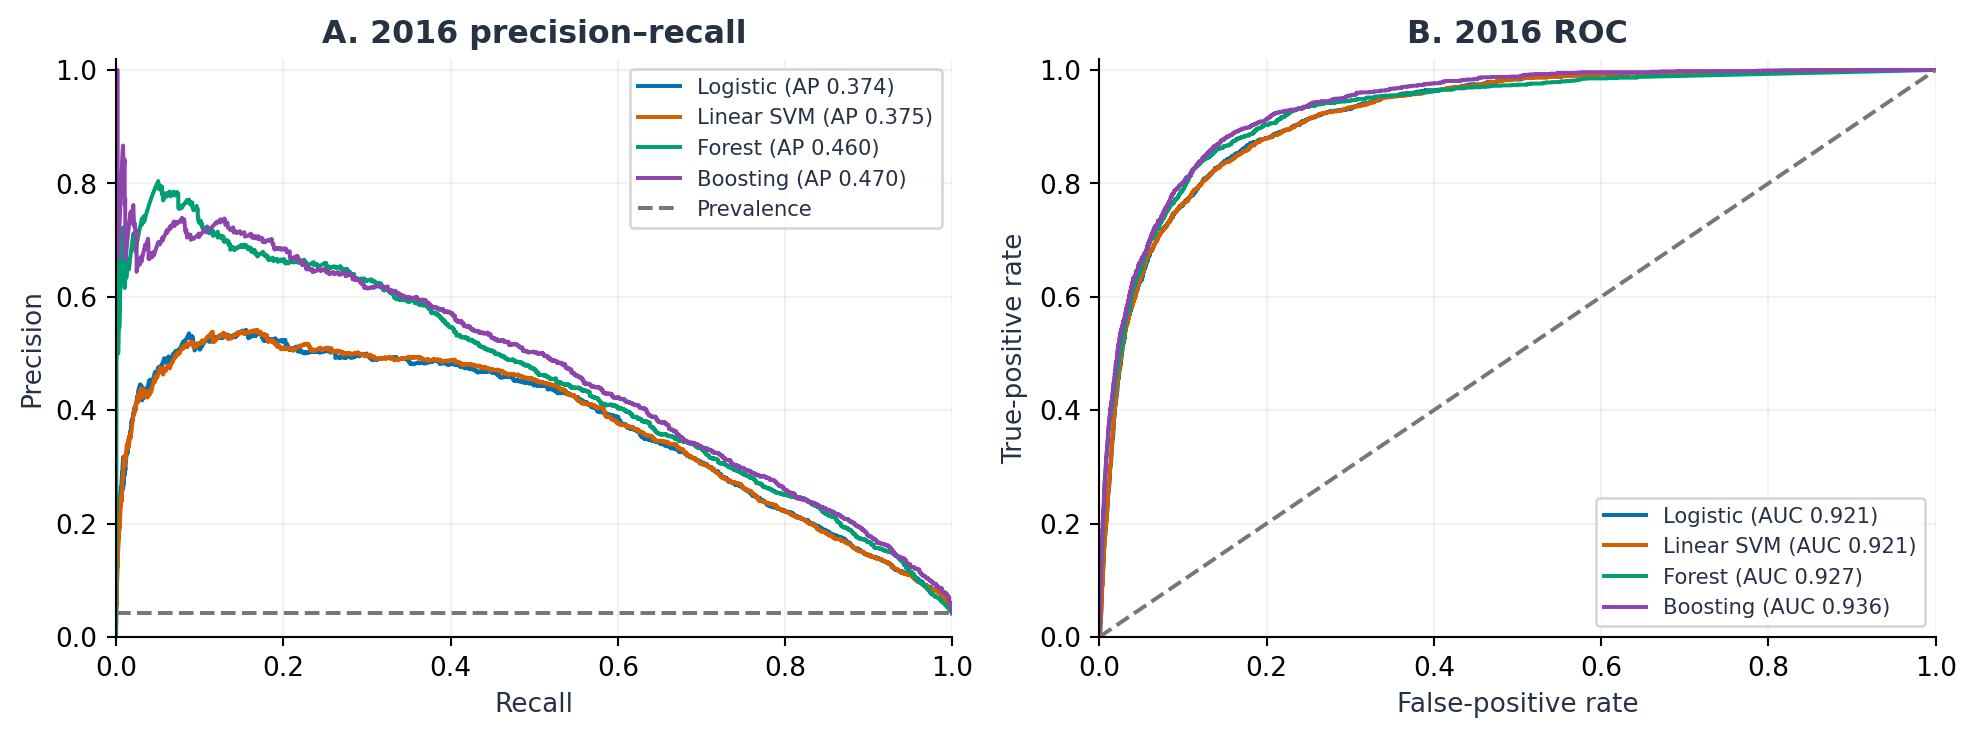

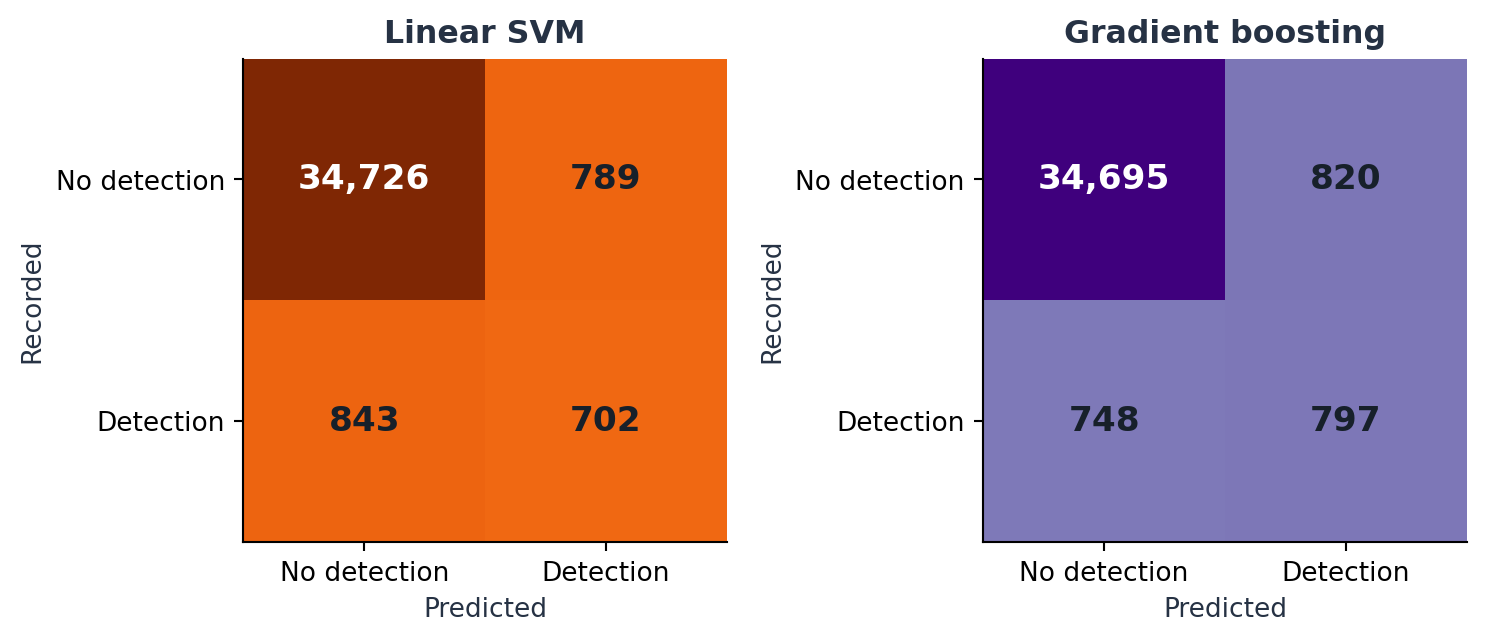

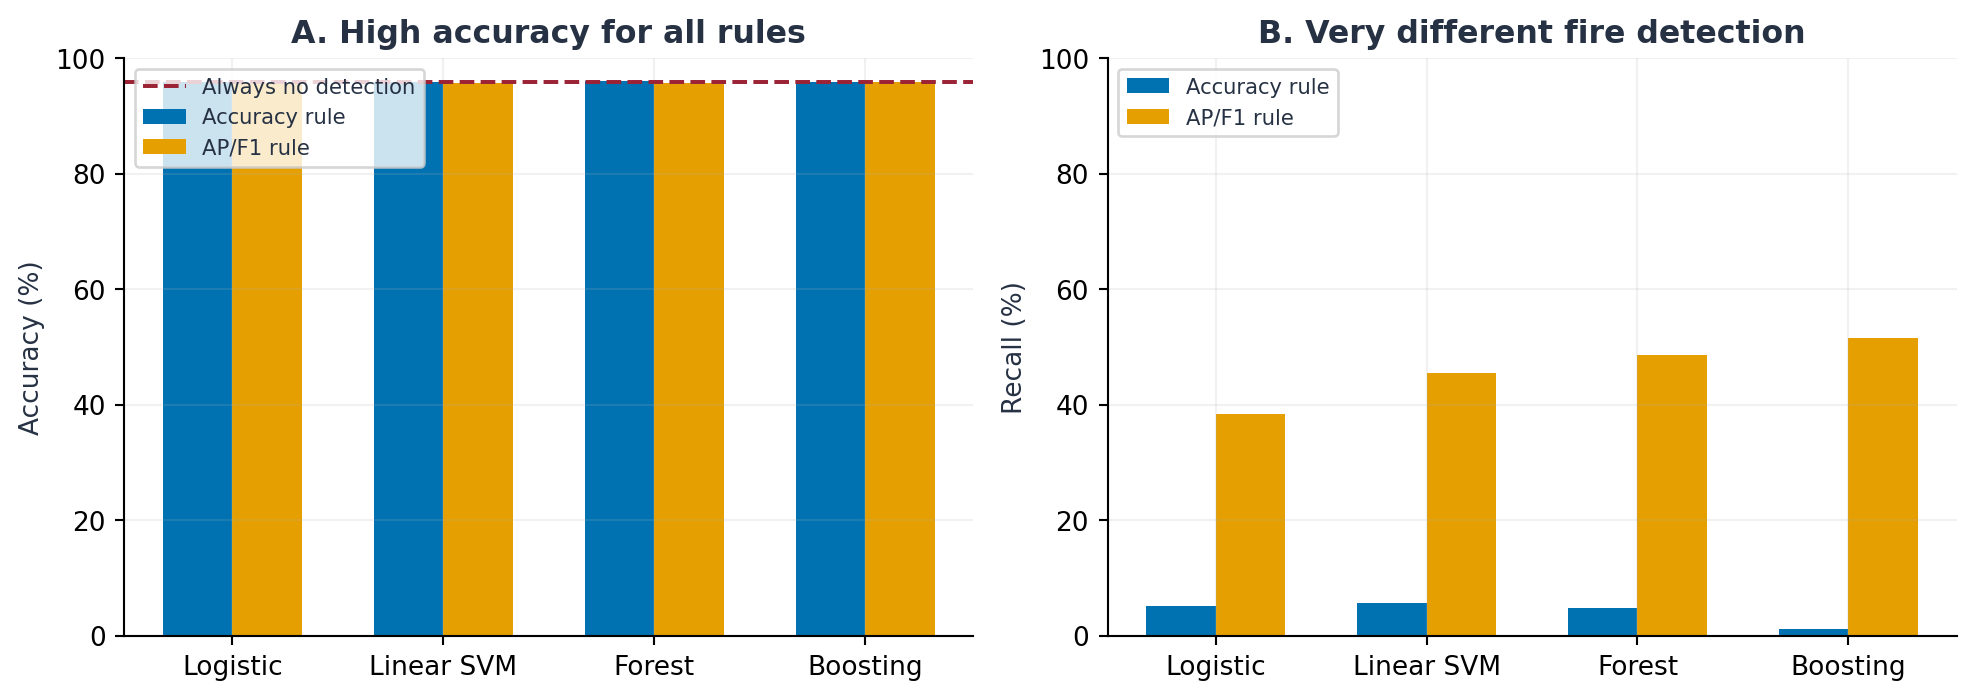

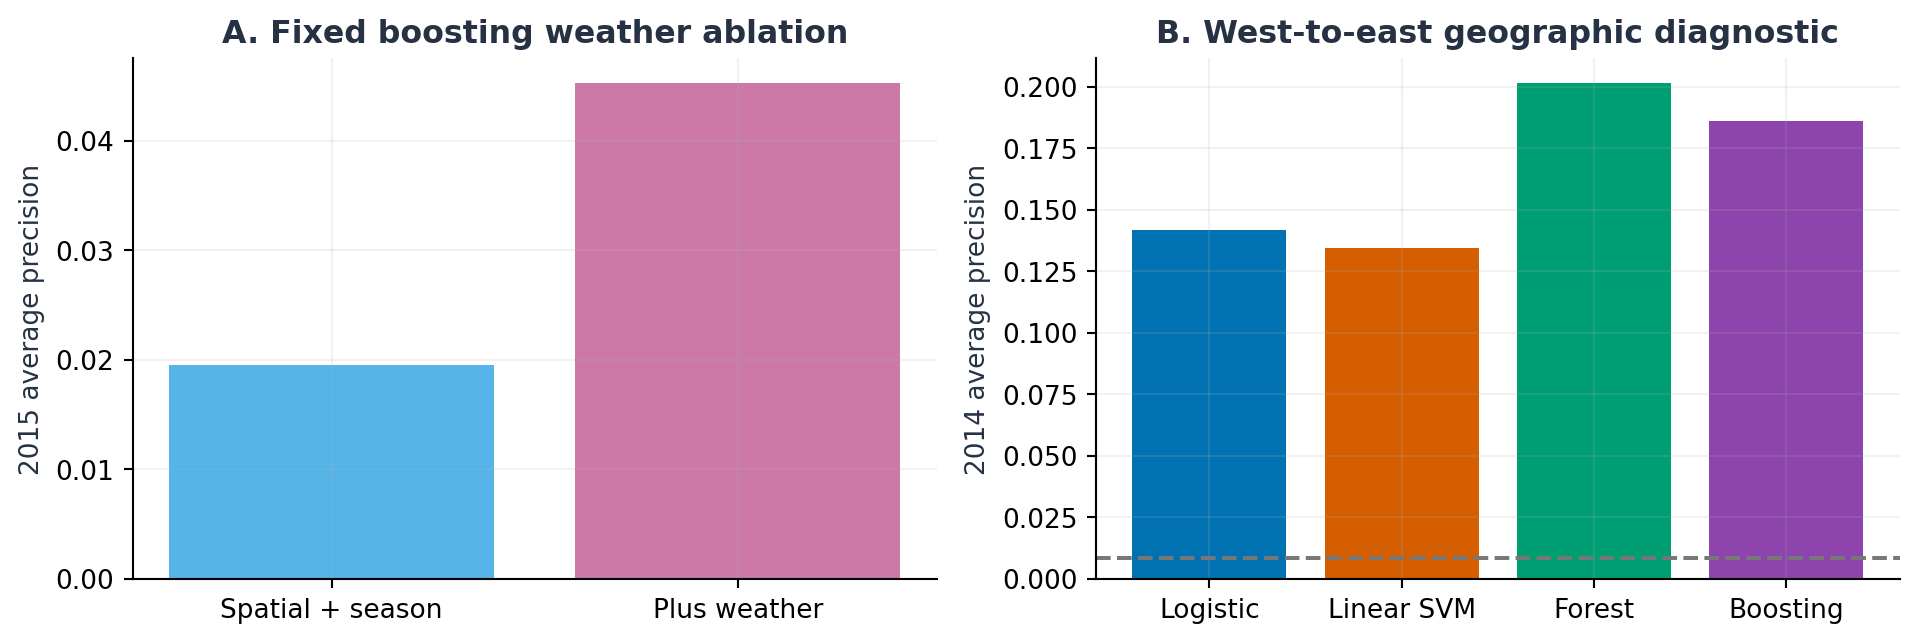

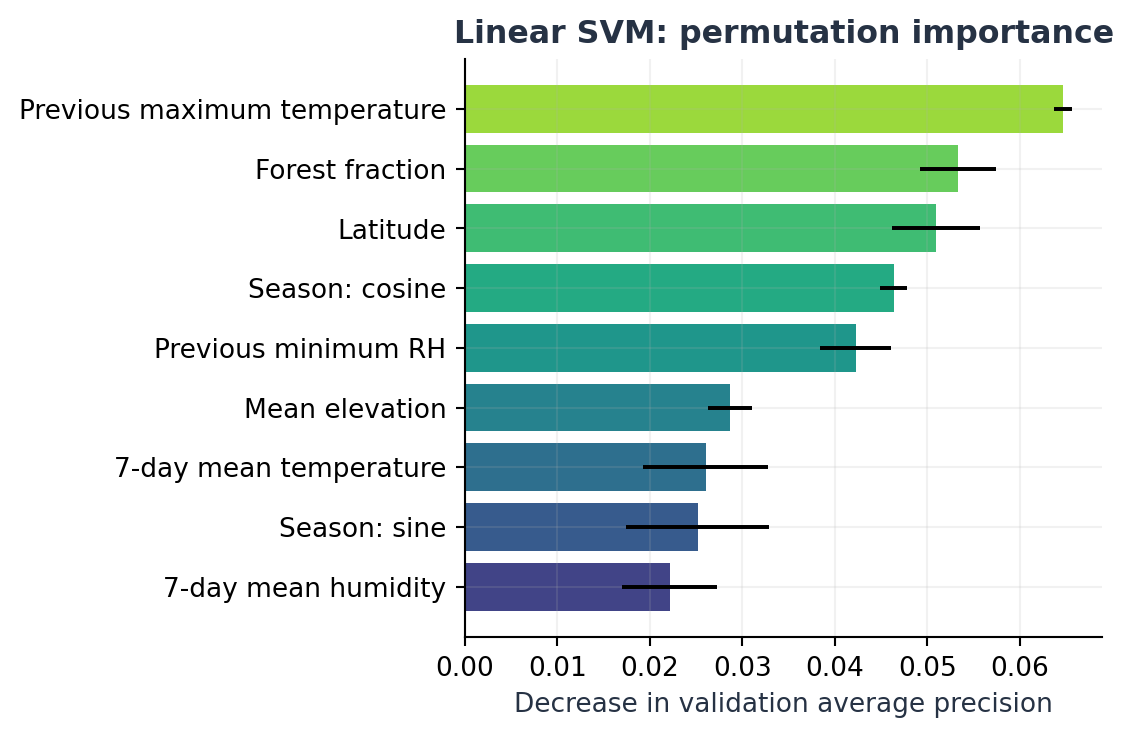

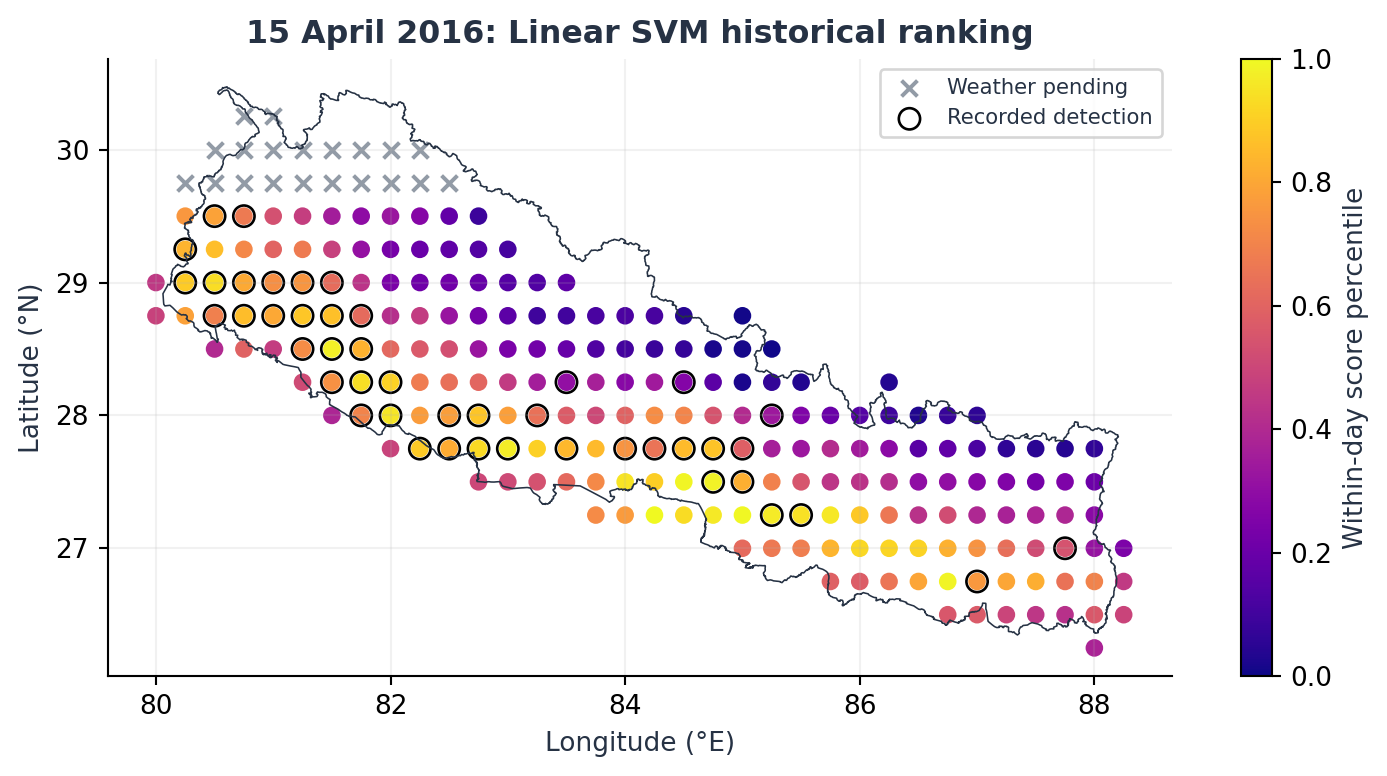

In [6]:
for name in ['coverage_counts','distributions','correlation','curves','confusions','accuracy_recall','diagnostics','importance','historical_map']:
    p=ROOT/'research/overleaf/images'/f'{name}.png'
    display(Image(filename=str(p),width=900))


## 7. Sensitivity, limitations, and interpretation

The fixed-complexity weather ablation changes validation AP from 0.0195 with location/terrain/season to 0.0453 after adding lagged weather. This supports incremental predictive information in this experiment; it does not show a causal effect. A geographically separated diagnostic gives a different ranking, demonstrating limited transfer evidence. Weekly block-bootstrap AP intervals overlap, so measured differences do not establish statistical superiority.

Important limitations are incomplete and geographically ordered weather coverage; unverified no-detection labels without satellite cloud/overpass masks; unusually sparse 2015 detections; one fixed forest baseline; and earlier exploratory exposure to overlapping test outcomes. The analysis predicts recorded detections at previously represented locations, not confirmed ignitions, burned area, or national operational risk. Next steps are to finish the remaining weather locations, preserve a new data snapshot, and evaluate multiple forward-time validation folds and a genuinely untouched test period.

In [7]:
display(pd.read_csv(ROOT/'research/results/ablation.csv'))
display(pd.read_csv(ROOT/'research/results/spatial_diagnostic.csv'))
display(pd.read_csv(ROOT/'research/results/ap_intervals.csv'))


,features,count,validation_ap
0,"Terrain, location and season",9,0.019466
1,Plus lagged weather,21,0.045271


,model,training_rows,evaluation_rows,positive_days,average_precision,roc_auc
0,Logistic regression,90870,32120,262,0.141739,0.952102
1,Linear SVM,90870,32120,262,0.134500,0.952115
2,Random forest,90870,32120,262,0.201502,0.939685
3,Gradient boosting,90870,32120,262,0.185841,0.957160


,model,ap_lower,ap_upper,bootstrap_repeats
0,Logistic regression,0.124452,0.463556,200
1,Linear SVM,0.184785,0.459583,200
2,Random forest,0.253794,0.546954,200
3,Gradient boosting,0.269220,0.566429,200


## References and accompanying files

The paper's full APA 7 reference list is in `research/overleaf/references.tex`. The Overleaf source and colourful figures are packaged together as `research/overleaf/Nepal_Forest_Fire_Overleaf_Project.zip`. Experiment definitions are in `research_experiments.py`; figure code is in `research_figures.py`. Cite ICIMOD as the source/distributor of the primary Nepal incident dataset and MODIS as the observing instrument.